In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

## Load Experiment

First, we load the experiment from the `results` folder. Each experiment is collected into a single `.parquet` file. Its rows contain recognition results for each configuration (combination) and each fold (flattened).

In [2]:
# Configuration which experiment should be loaded.
EXPERIMENT_NAMES = [
    "sface_anonymizers_no_aggregation",
    "arcface_anonymizers_no_aggregation",
    "ghostfacenet_anonymizers_no_aggregation",
]
RESULTS_PATH = Path("../../results")

In [3]:
# Load the experiment dataset.
EXPERIMENT_DATA = pd.concat([pd.read_parquet(RESULTS_PATH / f"{name}.parquet") for name in EXPERIMENT_NAMES])
EXPERIMENT_DATA

,identity,video,observations,top-1,top-5,top-10,predicted,fold,gallery_frame_anonymization,gallery_frame_aggregation,gallery_frame_embedding,gallery_embedding_aggregation,samples_frame_anonymization,samples_frame_aggregation,samples_frame_embedding,samples_embedding_aggregation,score_aggregation,pipeline
0,Aaron_Eckhart,2,56,1.0,1.0,1.0,Aaron_Eckhart,1,none,video_none,sface,video_none,none,video_none,sface,video_none,max_max,frame
1,Abdel_Aziz_Al-Hakim,0,75,1.0,1.0,1.0,Abdel_Aziz_Al-Hakim,1,none,video_none,sface,video_none,none,video_none,sface,video_none,max_max,frame
2,Abdullah_Gul,1,61,1.0,1.0,1.0,Abdullah_Gul,1,none,video_none,sface,video_none,none,video_none,sface,video_none,max_max,frame
3,Abel_Pacheco,3,52,1.0,1.0,1.0,Abel_Pacheco,1,none,video_none,sface,video_none,none,video_none,sface,video_none,max_max,frame
4,Adam_Sandler,0,48,1.0,1.0,1.0,Adam_Sandler,1,none,video_none,sface,video_none,none,video_none,sface,video_none,max_max,frame
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30267,Yuri_Fedotov,4,49,1.0,1.0,1.0,Yuri_Fedotov,3,pixelation,video_none,ghostfacenet,video_none,pixelation,video_none,ghostfacenet,video_none,max_max,frame
30268,Zhang_Ziyi,1,75,0.0,0.0,0.0,Matt_Anderson,3,pixelation,video_none,ghostfacenet,video_none,pixelation,video_none,ghostfacenet,video_none,max_max,frame
30269,Zhong_Nanshan,5,75,1.0,1.0,1.0,Zhong_Nanshan,3,pixelation,video_none,ghostfacenet,video_none,pixelation,video_none,ghostfacenet,video_none,max_max,frame
30270,Zoran_Djindjic,2,75,0.0,0.0,0.0,Tim_Pawlenty,3,pixelation,video_none,ghostfacenet,video_none,pixelation,video_none,ghostfacenet,video_none,max_max,frame


## Visualize accuracy

The following compares the recognition accuracy (i.e., top-1, top-5, top-10) of the three recognizers
against each sample anonymization, with no aggregation on either leg.

The gallery is held at `anonymization = none`, so each cell is the headline pairing: a clear gallery
queried with anonymized samples. The loaded results also contain *anonymized* galleries, which this
figure does not key on — pooling them would average four gallery conditions into every cell and roughly
halve the clear/clear diagonal. An assertion below fails if any other unkeyed configuration column varies.

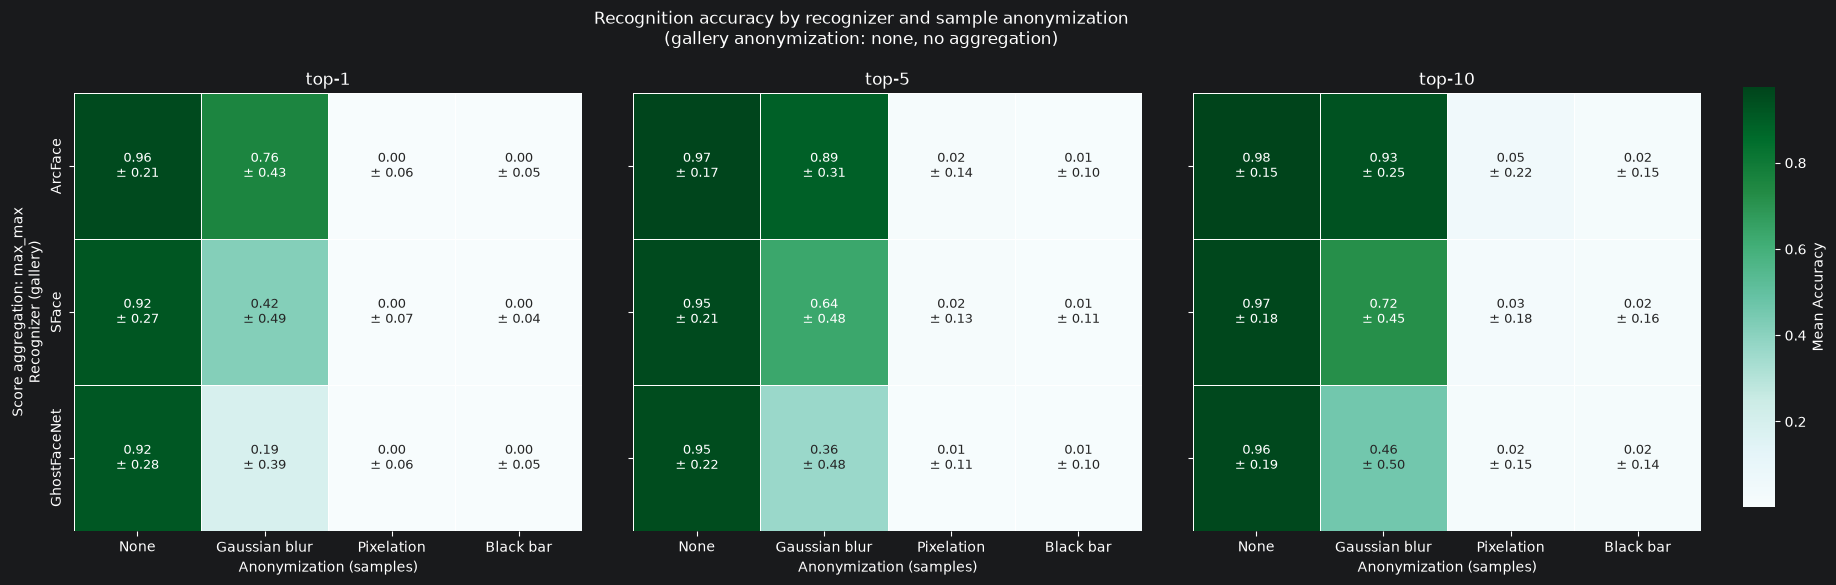

In [8]:
# Rename labels once, on the full dataset. Both legs' recognizers are renamed, so that the
# pairing check below compares like with like.
RECOGNIZER_LABELS = {"sface": "SFace", "arcface": "ArcFace", "ghostfacenet": "GhostFaceNet"}
data = EXPERIMENT_DATA.replace(
    {
        "samples_frame_anonymization": {
            "none": "None",
            "gaussianblur": "Gaussian blur",
            "blackbar": "Black bar",
            "pixelation": "Pixelation",
        },
        "gallery_frame_embedding": RECOGNIZER_LABELS,
        "samples_frame_embedding": RECOGNIZER_LABELS,
    }
)

# The headline pairing: what the attacker holds is clear, what they observe is anonymized.
# These results also contain anonymized galleries, and the plot does not key on them, so
# without this filter every cell would be a mean over all four gallery conditions --
# ArcFace clear/clear reads 0.49 pooled against 0.96 on a clear gallery.
GALLERY_ANONYMIZATION = "none"
data = data[data["gallery_frame_anonymization"] == GALLERY_ANONYMIZATION]

# One column per metric, one row per score aggregation
metrics = ["top-1", "top-5", "top-10"]
score_aggs = data["score_aggregation"].unique()  # or a fixed list, e.g. ["max_mean", ...]

# Guard against pooling a dimension again: every configuration column the plot does not key
# on must be constant, or its cells average over conditions the figure never names. The two
# legs' recognizers are checked as a pair, since the index names one recognizer for both.
KEYED = {"gallery_frame_embedding", "samples_frame_embedding", "samples_frame_anonymization", "score_aggregation"}
config_columns = [c for c in data.columns if c.startswith(("gallery_", "samples_"))] + ["score_aggregation", "pipeline"]
assert (data["gallery_frame_embedding"] == data["samples_frame_embedding"]).all(), (
    "the legs use different recognizers, so the index no longer names one recognizer"
)
pooled = {c: sorted(data[c].unique()) for c in config_columns if c not in KEYED and data[c].nunique() > 1}
assert not pooled, f"unkeyed columns vary, so each cell pools them: {pooled}"

# Shared ordering across all panels (based on one reference metric)
ORDER_METRIC = "top-1"
agg_order = data.groupby("gallery_frame_embedding")[ORDER_METRIC].mean().sort_values(ascending=False).index
embedding_order = data.groupby("samples_frame_anonymization")[ORDER_METRIC].mean().sort_values(ascending=False).index

# Build all pivots first so we can find a shared color range
pivots = {
    (m, s): data[data["score_aggregation"] == s]
    .pivot_table(
        index="gallery_frame_embedding",
        columns="samples_frame_anonymization",
        values=m,
        aggfunc="mean",
    )
    .reindex(index=agg_order, columns=embedding_order)
    for m in metrics
    for s in score_aggs
}
vmin = min(p.min().min() for p in pivots.values())
vmax = max(p.max().max() for p in pivots.values())

# Spread per cell: "std" for standard deviation, "sem" for standard error of the mean
SPREAD = "std"

spreads = {
    (m, s): data[data["score_aggregation"] == s]
    .pivot_table(
        index="gallery_frame_embedding",
        columns="samples_frame_anonymization",
        values=m,
        aggfunc=SPREAD,
    )
    .reindex(index=agg_order, columns=embedding_order)
    for m in metrics
    for s in score_aggs
}

def make_labels(mean_df, spread_df):
    return (
            mean_df.map(lambda v: f"{v:.2f}")
            + "\n± "
            + spread_df.map(lambda v: f"{v:.2f}" if pd.notna(v) else "n/a")
    )

fig, axes = plt.subplots(
    len(score_aggs),
    len(metrics),
    figsize=(7 * len(metrics), 6 * len(score_aggs)),
    sharex=True,
    sharey=True,
    squeeze=False,  # always 2D, even with a single row or column
)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # one colorbar for all panels

for r, s in enumerate(score_aggs):
    for c, m in enumerate(metrics):
        ax = axes[r, c]
        first = r == 0 and c == 0
        sns.heatmap(
            pivots[(m, s)],
            ax=ax,
            annot=make_labels(pivots[(m, s)], spreads[(m, s)]),
            fmt="",
            annot_kws={"fontsize": 9},
            #annot=True,
            #fmt=".3f",
            cmap="BuGn",
            vmin=vmin,
            vmax=vmax,
            linewidths=0.5,
            linecolor="w",
            cbar=first,
            cbar_ax=cbar_ax if first else None,
            cbar_kws={"label": "Mean Accuracy"},
        )
        # Column titles (metric) on top row only
        ax.set_title(m if r == 0 else "")
        # x-label on bottom row only
        ax.set_xlabel("Anonymization (samples)" if r == len(score_aggs) - 1 else "")
        # Row label (score aggregation) on first column only
        ax.set_ylabel(f"Score aggregation: {s}\nRecognizer (gallery)" if c == 0 else "")

fig.suptitle(
    "Recognition accuracy by recognizer and sample anonymization\n"
    f"(gallery anonymization: {GALLERY_ANONYMIZATION}, no aggregation)",
    y=0.98,
)
fig.subplots_adjust(right=0.9, top=0.84, wspace=0.1, hspace=0.1)
plt.show()